# 04 · Baselines

What the multi-exit model has to beat. Four reference points, in increasing
order of what they concede:

| Baseline | Concedes | If it wins, then… |
|---|---|---|
| Prevalence / logistic regression | nothing | the features barely matter |
| **XGBoost** | tabular signal, no graph | the patient-similarity graph adds nothing |
| GCN / GAT | graph, fixed shallow depth | depth is not the useful axis |
| SAS-GNN full depth | graph + depth, no early exit | exits cost accuracy rather than saving compute |
| Fixed-threshold early exit | exits, but hand-tuned | the *learned* halting policy is unnecessary |

XGBoost is the one that matters most. HANDOVER §6.2 records that on the first
synthetic cohort XGBoost beat every GNN, because the labels were a pure
function of each patient's own feature row and there was no relational signal
to propagate. Notebook 03 tests whether real data avoids that; this notebook is
where the consequence shows up as a number.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, graph_build as gb
from src.data_prep import make_splits, impute_and_scale
from src.train import set_seed, get_device
from src.evaluate import auroc, predictive_metrics, calibration_metrics
import torch, matplotlib.pyplot as plt

cfg = mimic_cfg()
set_seed(cfg["seed"])
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
train, val, test = make_splits(y, cfg["seed"])
X = impute_and_scale(X_raw, train)
data = gb.build_graph(X, y, (train, val, test), cfg, meta=meta, cache_dir=CACHE)

device = get_device()
data = data.to(device)
print(gb.describe(data))
print("device:", device)

nodes=17663 edges=426496 avg_degree=24.15 features=542 prevalence={'train': 0.10776635259389877, 'val': 0.10784036666154861, 'test': 0.10784036666154861}
device: cuda


## Reference floors

In [2]:
from sklearn.linear_model import LogisticRegression
import scipy.sparse as sp

results = {}

lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X[train], y[train])
p_lr = lr.predict_proba(X)[:, 1]
results["logistic_regression"] = {
    "test_auroc": auroc(y[test], p_lr[test]),
    **predictive_metrics(y[test], p_lr[test], cfg["eval"]["operating_sensitivity"])}

# Neighbour averaging: no learning at all, just the graph. This is the floor
# any GNN must clear to justify calling itself a graph model.
ei = data.edge_index.cpu().numpy()
n = len(y)
A = sp.coo_matrix((np.ones(ei.shape[1]), (ei[0], ei[1])), shape=(n, n)).tocsr()
num = A @ np.where(train, y, 0.0)
den = A @ train.astype(float)
p_nbr = np.divide(num, den, out=np.full(n, y[train].mean()), where=den > 0)
results["neighbour_average"] = {
    "test_auroc": auroc(y[test], p_nbr[test]),
    **predictive_metrics(y[test], p_nbr[test], cfg["eval"]["operating_sensitivity"])}

for k, v in results.items():
    print(f"{k:22s} test AUROC {v['test_auroc']:.4f}  AUPRC {v['auprc']:.4f}")

logistic_regression    test AUROC 0.8803  AUPRC 0.5320
neighbour_average      test AUROC 0.8246  AUPRC 0.4523


## XGBoost — the non-graph reference

Runs out-of-process. On macOS/arm64 xgboost and torch cannot share an OpenMP
runtime (torch-then-xgboost segfaults, the reverse deadlocks), so
`src/_omp_guard.run_xgb_worker` shells out to a torch-free subprocess. That
isolation is unnecessary on this Linux kernel but harmless, and keeping one
code path avoids a platform-conditional branch that would only be exercised on
one machine.

In [3]:
from src.baselines import xgboost_baseline

t0 = time.time()
xgb_out, xgb_metrics, p_xgb = xgboost_baseline(X, y, (train, val, test), seed=cfg["seed"])
results["xgboost"] = {
    "test_auroc": xgb_metrics["test_auroc"],
    **predictive_metrics(y[test], p_xgb, cfg["eval"]["operating_sensitivity"])}
print(f"xgboost  val {xgb_metrics['val_auroc']:.4f}  test {xgb_metrics['test_auroc']:.4f}"
      f"  [{time.time()-t0:.1f}s]")

xgboost  val 0.8824  test 0.8951  [5.9s]


## Graph baselines

In [4]:
from src.baselines import GCN, GAT, train_plain_gnn

def eval_plain(model):
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(data.x, data.edge_index, data.edge_weight), -1)[:, 1]
    p = p.cpu().numpy()
    yt = data.y.cpu().numpy()
    m = data.test_mask.cpu().numpy()
    return {"test_auroc": auroc(yt[m], p[m]),
            **predictive_metrics(yt[m], p[m], cfg["eval"]["operating_sensitivity"]),
            **calibration_metrics(yt[m], p[m], cfg["eval"]["n_bins_ece"])}, p

for name, ctor in [("gcn", lambda: GCN(data.x.shape[1], cfg["model"]["hidden_dim"],
                                       n_layers=2, dropout=cfg["model"]["dropout"])),
                   ("gat", lambda: GAT(data.x.shape[1], cfg["model"]["hidden_dim"],
                                       n_layers=2, dropout=cfg["model"]["dropout"]))]:
    set_seed(cfg["seed"])
    t0 = time.time()
    model, best_val = train_plain_gnn(ctor().to(device), data, cfg)
    results[name], _ = eval_plain(model)
    print(f"{name:22s} val {best_val:.4f}  test {results[name]['test_auroc']:.4f}"
          f"  [{time.time()-t0:.1f}s]")

gcn                    val 0.8593  test 0.8659  [3.2s]


gat                    val 0.8579  test 0.8658  [4.3s]


## SAS-GNN at full depth

The multi-exit model's own backbone, run without exits. Isolates what the
weight-tied ODE-style propagation buys before any halting logic is added.

In [5]:
from src.train import train_model
from src.evaluate import evaluate_model, calibrate_on_val

set_seed(cfg["seed"])
t0 = time.time()
full_model, full_hist, _full_best = train_model(data, cfg, use_exits=False,
                                                verbose=False)
T = calibrate_on_val(full_model, data)
res_full = evaluate_model(full_model, data, cfg, split="test", temperature=T)
results["sasgnn_full_depth"] = {
    "test_auroc": res_full["predictive"]["auroc"], **res_full["predictive"]}
print(f"sasgnn_full_depth      test {res_full['predictive']['auroc']:.4f}"
      f"  ECE {res_full['calibration']['ece']:.4f}  [{time.time()-t0:.1f}s]")

sasgnn_full_depth      test 0.8855  ECE 0.1208  [8.9s]


## Fixed-threshold early exit

A GCN with softmax-entropy exits at hand-set thresholds: early exit without a
learned halting policy. This is the control that decides whether the learned
policy in notebook 05 is earning its complexity or just reproducing what a
hand-tuned threshold already does.

In [6]:
from src.baselines import fixed_threshold_ee

set_seed(cfg["seed"])
t0 = time.time()
ee_out = fixed_threshold_ee(data, cfg)
print(f"fixed_threshold_ee     [{time.time()-t0:.1f}s]")
print({k: (round(v, 4) if isinstance(v, float) else v)
       for k, v in ee_out.items() if not hasattr(v, "shape")})

fixed_threshold_ee     [11.8s]
{'avg_exit_depth': 4.618}


## Comparison

                     test_auroc   auprc  sensitivity  specificity     ppv
xgboost                  0.8951  0.5592       0.9003       0.6805  0.2541
sasgnn_full_depth        0.8855  0.5586       0.9003       0.6853  0.2569
logistic_regression      0.8803  0.5320       0.9003       0.6624  0.2438
gcn                      0.8659  0.5127       0.9003       0.6339  0.2291
gat                      0.8658  0.5040       0.9003       0.6199  0.2226
neighbour_average        0.8246  0.4523       1.0000       0.0000  0.1078


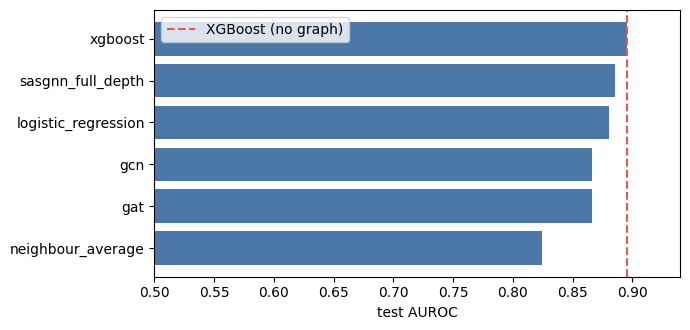

In [7]:
tab = pd.DataFrame(results).T
cols = [c for c in ["test_auroc", "auprc", "sensitivity", "specificity", "ppv"]
        if c in tab.columns]
tab = tab[cols].sort_values("test_auroc", ascending=False)
print(tab.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(tab.index[::-1], tab["test_auroc"][::-1], color="#4C78A8")
ax.axvline(results["xgboost"]["test_auroc"], color="#E45756", ls="--",
           label="XGBoost (no graph)")
ax.set_xlabel("test AUROC"); ax.set_xlim(0.5, None); ax.legend()
plt.tight_layout(); plt.show()

## Reading the result

The comparison that decides the project's framing:

- **GNNs above XGBoost** — the patient-similarity graph carries signal that
  tabular boosting cannot reach, and adaptive depth over that graph is a
  coherent thing to study.
- **XGBoost at or above every GNN** — the same failure as HANDOVER §6.2, now on
  real data. The honest conclusion would be that this cohort's mortality signal
  is essentially tabular, and the early-exit contribution must then be framed
  as a compute result, not an accuracy one. Notebook 03's hop-AUROC curve
  should have predicted which of these happened.

Note also the gap between `neighbour_average` and the trained GNNs. A trained
model that barely clears plain neighbour averaging is not learning much beyond
smoothing the labels it was given.

In [8]:
json.dump({k: {kk: float(vv) for kk, vv in v.items() if isinstance(vv, (int, float))}
           for k, v in results.items()},
          open(f"{CACHE}/baselines.json", "w"), indent=2)
print("wrote baselines.json")

wrote baselines.json


**Next:** `05_eegnn_multiexit` — the multi-exit model with learned halting,
per-exit calibration, and the exit distribution.